# ĐỒ ÁN NT120 — PHÁT HIỆN VÀ PHÂN LOẠI TẤN CÔNG MẠNG SDN

**Đề tài:** So sánh Decision Tree, Random Forest và XGBoost trên bộ dữ liệu **InSDN**.

**Phiên bản nhập môn:** EDA → làm sạch `NaN/null/inf` → chia train/test → điền thiếu → cân bằng số mẫu **trên train** → huấn luyện multiclass → đánh giá thêm binary.

- **Multiclass:** phân loại `Normal`, `DDoS`, `DoS`, `Probe`, `BFA`, `BOTNET`, `U2R`, ...
- **Binary:** từ dự đoán multiclass quy về `Normal` (0) / `Attack` (1), **không train mô hình binary thứ hai**.

**Cách dùng:** Đặt CSV vào `data/InSDN` hoặc sửa `DATA_DIR` tại mục 3 rồi chạy các ô lần lượt. Notebook **không có số liệu đánh giá dựng sẵn**: các bảng, biểu đồ sẽ sinh ra từ dữ liệu thực khi bạn chạy.


## Mục lục

1. Giới thiệu và phát biểu bài toán
2. Khảo sát các giải pháp liên quan
3. Thiết lập môi trường và nạp dữ liệu (EDA)
4. Tiền xử lý dữ liệu
5. Phương pháp tiếp cận
6. Thực nghiệm và đánh giá kết quả
7. Phân tích và thảo luận
8. Kết luận và hướng phát triển
9. Đóng góp của các thành viên
10. Tài liệu tham khảo

## 1. Giới thiệu và phát biểu bài toán

**Bối cảnh:** Software-Defined Networking (SDN) giúp quản lý mạng tập trung nhưng cũng có nguy cơ chịu các cuộc tấn công DoS, DDoS, Probe và các dạng khác. Bộ dữ liệu InSDN chứa các bản ghi lưu lượng mạng (network flow) với nhãn tương ứng.

**Đầu vào:** Các đặc trưng số của network flow. **Đầu ra chính:** Một trong các loại lưu lượng/tấn công (**multiclass**). **Đầu ra suy ra:** `Normal` hay `Attack` (**binary**).

**Mục tiêu:** Huấn luyện và so sánh Decision Tree, Random Forest, XGBoost; đánh giá Accuracy, Precision, Recall, F1-score và Confusion Matrix cho cả multiclass và binary.

**Giới hạn:** Đây là phân loại trên dữ liệu có nhãn, chưa phải hệ thống giám sát mạng thời gian thực. Một số nhãn rất hiếm nên kết quả từng lớp cần được diễn giải thận trọng.

## 2. Khảo sát các giải pháp liên quan

| Mô hình | Ý tưởng chính | Đặc điểm |
|---|---|---|
| **Decision Tree** | Dự đoán bằng các luật chia nhánh | Dễ giải thích, dễ overfit |
| **Random Forest** | Kết hợp nhiều cây quyết định | Thường ổn định hơn một cây |
| **XGBoost** | Xây các cây theo cách cải thiện dần lỗi dự đoán | Thường hiệu quả nhưng cần thêm thư viện |

Đồ án dùng cùng dữ liệu và cách chia train/test để so sánh ba mô hình. Do các lớp có số lượng rất chênh lệch, **Macro F1** được xem cùng với Accuracy để tránh đánh giá quá lạc quan khi mô hình chỉ dự đoán tốt lớp phổ biến.

## 3. Thiết lập môi trường và nạp dữ liệu

### 3.1. Thư viện và cấu hình

Cài một lần (nếu cần):

```bash
pip install pandas numpy matplotlib scikit-learn xgboost
```

Chỉ cần sửa đường dẫn `DATA_DIR` cho phù hợp máy của bạn.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

DATA_DIR = Path("/kaggle/input/datasets/badcodebuilder/insdn-dataset/InSDN_DatasetCSV")  # Sửa đường dẫn tới thư mục CSV của bạn
RANDOM_STATE = 42
SAMPLES_PER_CLASS = 5000  # Mỗi nhãn trong TRAIN sau cân bằng có 5.000 dòng


### 3.2. Đọc dữ liệu

Đọc tất cả file `.csv` trong thư mục và ghép thành một bảng. Nếu chỉ có một CSV, đoạn code vẫn chạy bình thường.

In [2]:
csv_files = sorted(DATA_DIR.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"Không tìm thấy CSV trong {DATA_DIR.resolve()}. Hãy sửa DATA_DIR.")

print("Các file dữ liệu:")
for f in csv_files:
    print("-", f.name)

df = pd.concat([pd.read_csv(f, low_memory=False) for f in csv_files], ignore_index=True)
df.columns = df.columns.str.strip()

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Các file dữ liệu:
- Normal_data.csv
- OVS.csv
- metasploitable-2.csv
Kích thước dữ liệu: (343889, 84)


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,185.127.17.56-192.168.20.133-443-53648-6,185.127.17.56,443,192.168.20.133,53648,6,5/2/2020 13:58,245230,44,40,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Normal
1,185.127.17.56-192.168.20.133-443-53650-6,192.168.20.133,53650,185.127.17.56,443,6,5/2/2020 13:58,1605449,107,149,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Normal
2,192.168.20.133-192.168.20.2-35108-53-6,192.168.20.133,35108,192.168.20.2,53,6,5/2/2020 13:58,53078,5,5,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Normal
3,192.168.20.133-192.168.20.2-35108-53-6,192.168.20.2,53,192.168.20.133,35108,6,5/2/2020 13:58,6975,1,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Normal
4,154.59.122.74-192.168.20.133-443-60900-6,192.168.20.133,60900,154.59.122.74,443,6,5/2/2020 13:58,190141,13,16,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Normal


### 3.3. EDA — thông tin chung

Xem tên các cột, kiểu dữ liệu, thống kê một số đặc trưng. Bước này giúp biết dữ liệu có những gì trước khi xử lý.

In [3]:
df.info()
display(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343889 entries, 0 to 343888
Data columns (total 84 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Flow ID            343889 non-null  object 
 1   Src IP             343889 non-null  object 
 2   Src Port           343889 non-null  int64  
 3   Dst IP             343889 non-null  object 
 4   Dst Port           343889 non-null  int64  
 5   Protocol           343889 non-null  int64  
 6   Timestamp          343889 non-null  object 
 7   Flow Duration      343889 non-null  int64  
 8   Tot Fwd Pkts       343889 non-null  int64  
 9   Tot Bwd Pkts       343889 non-null  int64  
 10  TotLen Fwd Pkts    343889 non-null  float64
 11  TotLen Bwd Pkts    343889 non-null  float64
 12  Fwd Pkt Len Max    343889 non-null  int64  
 13  Fwd Pkt Len Min    343889 non-null  int64  
 14  Fwd Pkt Len Mean   343889 non-null  float64
 15  Fwd Pkt Len Std    343889 non-null  float64
 16  Bw

,Src Port,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,343889.00,343889.00,343889.00,3.438890e+05,343889.00,343889.00,343889.00,3.438890e+05,343889.00,343889.00,...,343889.00,343889.0,3.438890e+05,343889.00,3.438890e+05,3.438890e+05,3.438890e+05,343889.00,3.438890e+05,3.438890e+05
mean,21982.66,8072.50,4.96,6.737171e+06,6.16,6.12,731.06,8.335010e+03,115.69,4.45,...,1.44,0.0,6.385104e+04,31053.50,1.086384e+05,4.185579e+04,4.708172e+06,144361.31,4.843965e+06,4.581512e+06
std,23669.46,16275.41,4.86,2.183354e+07,1554.17,105.86,69652.89,3.429719e+05,666.52,31.29,...,39.47,0.0,7.852718e+05,503560.11,1.220601e+06,6.672299e+05,1.616113e+07,1653490.72,1.641612e+07,1.604560e+07
min,0.00,0.00,0.00,-1.540000e+02,0.00,1.00,0.00,0.000000e+00,0.00,0.00,...,0.00,0.0,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00
25%,0.00,0.00,0.00,1.700000e+01,0.00,2.00,0.00,0.000000e+00,0.00,0.00,...,0.00,0.0,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00
50%,443.00,80.00,6.00,2.530000e+03,0.00,2.00,0.00,0.000000e+00,0.00,0.00,...,0.00,0.0,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00
75%,43920.00,2495.00,6.00,1.208600e+04,2.00,4.00,30.00,3.000000e+01,30.00,0.00,...,1.00,0.0,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00
max,65518.00,65389.00,17.00,1.200000e+08,910748.00,34094.00,31600000.00,1.070000e+08,64239.00,3900.00,...,11180.00,0.0,1.040000e+08,68300000.00,1.040000e+08,1.040000e+08,1.200000e+08,73000000.00,1.200000e+08,1.200000e+08


### 3.4. EDA — phân bố nhãn

Đếm số mẫu từng lớp và vẽ biểu đồ. Với số lượng bạn đã quan sát, các lớp như `U2R` và `BOTNET` rất ít so với `DDoS` — đây là **Class Imbalance**.

,Số mẫu
Label,
Probe,98129
DDoS,73529
Normal,68424
DoS,53616
DDoS,48413
BFA,1405
Web-Attack,192
BOTNET,164
U2R,17


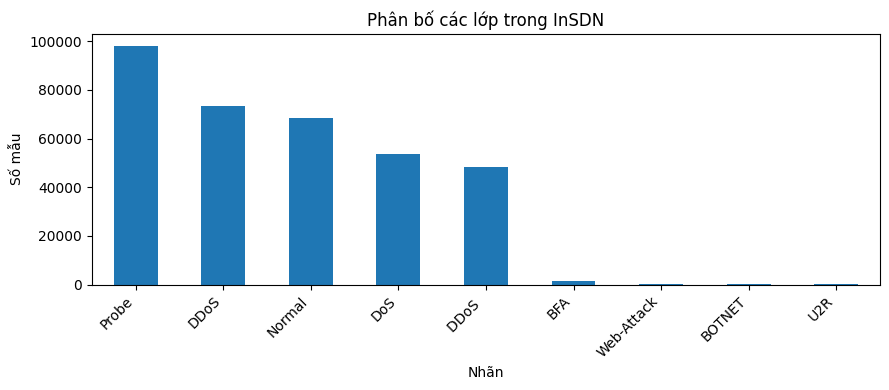

In [4]:
label_columns = [c for c in df.columns if c.lower() == "label"]
if not label_columns:
    raise ValueError("Không tìm thấy cột 'Label' trong dữ liệu.")
LABEL_COL = label_columns[0]

label_counts = df[LABEL_COL].value_counts(dropna=False)
display(label_counts.to_frame("Số mẫu"))

label_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Phân bố các lớp trong InSDN")
plt.xlabel("Nhãn")
plt.ylabel("Số mẫu")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3.5. EDA — dữ liệu thiếu, vô hạn và bản ghi trùng

- **NaN/Null**: dữ liệu bị thiếu.
- **`inf` / `-inf`**: giá trị vô hạn, thường xuất hiện khi tính tốc độ theo thời gian.
- **Trùng**: nhiều dòng giống hệt nhau.

Ở đây **chỉ thống kê**. Việc chuyển về dữ liệu hợp lệ thực hiện trong mục 4.


In [5]:
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
missing = df.isna().sum()
print("Các cột có NaN/null (trước xử lý):")
display(missing[missing > 0].sort_values(ascending=False))

# Kiểm tra inf/-inf trong những cột đã được pandas đọc là dạng số.
numeric_df = df.select_dtypes(include="number")
inf_count = int(np.isinf(numeric_df.to_numpy()).sum()) if not numeric_df.empty else 0
print("Giá trị +/-inf ở các cột số:", inf_count)
print("(Có thể có inf dạng chuỗi; sẽ kiểm tra lại sau khi ép sang số ở mục 4.)")


Số dòng trùng hoàn toàn: 1
Các cột có NaN/null (trước xử lý):


Series([], dtype: int64)

Giá trị +/-inf ở các cột số: 0
(Có thể có inf dạng chuỗi; sẽ kiểm tra lại sau khi ép sang số ở mục 4.)


### 3.6. Nhận xét EDA (điền sau khi chạy)

- Dữ liệu ban đầu: **[...]** dòng, **[...]** cột.
- Lớp nhiều nhất **[...]**, lớp ít nhất **[...]**.
- Số dòng trùng **[...]**, số giá trị `NaN` **[...]**, số giá trị `inf` **[...]**.
- **Kết luận:** Dữ liệu mất cân bằng; cần cân bằng nhãn tập huấn luyện và chú ý Recall/F1 của lớp hiếm.


## 4. Tiền xử lý dữ liệu

Các bước cơ bản:

1. Bỏ dòng thiếu nhãn, dòng trùng; chuẩn hóa nhãn `Normal`.
2. Bỏ các cột chứa định danh/nhãn phụ; chuyển đặc trưng sang số, thay `inf/-inf` bằng `NaN`.
3. Chia **train/test = 80/20** theo `stratify=y`.
4. Điền `NaN` bằng **median của train** (`SimpleImputer`); biến đổi test bằng chính median đó.
5. Cân bằng **chỉ tập train** bằng kết hợp **undersampling** (giảm số dòng lớp lớn) và **oversampling** (lấy lặp lại dòng lớp nhỏ). Trực quan hóa trước/sau.

**Không cân bằng test:** test vẫn có tỷ lệ tấn công như dữ liệu gốc, để đo kết quả thực tế hơn. `StandardScaler` không bắt buộc cho 3 mô hình cây này.


### 4.1. Làm sạch dữ liệu

Nếu chỉ có 1 dòng trùng thì sau làm sạch giảm 1 dòng là bình thường: việc mất cân bằng **không được giải quyết bằng xóa trùng**.

In [6]:
df_clean = df.dropna(subset=[LABEL_COL]).drop_duplicates().copy()
df_clean[LABEL_COL] = df_clean[LABEL_COL].astype(str).str.strip()
df_clean = df_clean[df_clean[LABEL_COL] != ""].copy()

# Gộp các cách viết của nhãn bình thường (không gộp các loại tấn công với nhau).
normal_mask = df_clean[LABEL_COL].str.lower().isin(["normal", "benign"])
df_clean.loc[normal_mask, LABEL_COL] = "Normal"

print("Trước làm sạch:", len(df))
print("Sau làm sạch:", len(df_clean))
print("Phân bố nhãn sau làm sạch:")
display(df_clean[LABEL_COL].value_counts().to_frame("Số mẫu"))

Trước làm sạch: 343889
Sau làm sạch: 343888
Phân bố nhãn sau làm sạch:


,Số mẫu
Label,
DDoS,121942
Probe,98129
Normal,68423
DoS,53616
BFA,1405
Web-Attack,192
BOTNET,164
U2R,17


### 4.2. Đặc trưng số X và nhãn y; làm sạch `inf/-inf`

Chỉ lấy các cột có thể biết khi nhận một network flow. Bỏ IP, Flow ID, thời gian và nhãn phụ để tránh **rò rỉ nhãn**.

- Dùng `pd.to_numeric(..., errors="coerce")` để đưa về số; giá trị không chuyển được thành `NaN`.
- Dùng `.replace([np.inf, -np.inf], np.nan)` để đổi giá trị vô hạn thành thiếu.
- **Không xóa toàn bộ dòng chứa `NaN`**, vì có thể mất nhiều dữ liệu. Bước 4.3 sẽ điền chúng bằng median.


In [7]:
# Bỏ các cột định danh hoặc có thể làm lộ nhãn.
def is_removed_column(col):
    name = col.lower().replace(" ", "").replace("_", "").replace("-", "")
    identifiers = {"flowid", "srcip", "dstip", "sourceip", "destinationip", "timestamp", "subcat"}
    return (name in identifiers or "label" in name or "attack" in name
            or "category" in name or name == "class")

feature_columns = [c for c in df_clean.columns if not is_removed_column(c)]
X = df_clean[feature_columns].apply(pd.to_numeric, errors="coerce")
y = df_clean[LABEL_COL]

# Kiểm tra số NaN và inf trước và sau khi thay thế.
nan_before = int(X.isna().sum().sum())
inf_before = int(np.isinf(X.to_numpy()).sum())
X = X.replace([np.inf, -np.inf], np.nan)

print("Số đặc trưng ứng viên:", X.shape[1])
print("NaN trước khi xử lý inf:", nan_before)
print("Inf/-Inf đã thay thành NaN:", inf_before)
print("NaN sau khi thay inf:", int(X.isna().sum().sum()))
print("Inf còn lại:", int(np.isinf(X.to_numpy()).sum()))
print("Các cột không dùng:", [c for c in df_clean.columns if c not in feature_columns])


Số đặc trưng ứng viên: 79
NaN trước khi xử lý inf: 0
Inf/-Inf đã thay thành NaN: 0
NaN sau khi thay inf: 0
Inf còn lại: 0
Các cột không dùng: ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label']


### 4.3. Chia train/test và điền `NaN`

- `stratify=y`: giữ gần đúng tỷ lệ nhãn khi chia dữ liệu.
- `SimpleImputer(strategy="median")`: **tính median trên train**, sau đó áp dụng cho cả train và test để tránh data leakage.
- Cột chỉ chứa giá trị thiếu trong train sẽ được bỏ.
- `LabelEncoder`: mã hóa tên nhãn thành số nguyên để huấn luyện.

**Tập test không bị resampling.** Tập này dùng chung cho cả đánh giá multiclass và binary.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Chỉ dùng những cột có ít nhất một giá trị hợp lệ trong TRAIN.
used_columns = X_train.columns[X_train.notna().any()]
if len(used_columns) == 0:
    raise ValueError("Không tìm thấy đặc trưng số hợp lệ. Hãy kiểm tra CSV.")
X_train = X_train[used_columns]
X_test = X_test[used_columns]

print("NaN train trước khi điền:", int(X_train.isna().sum().sum()))
print("NaN test trước khi điền:", int(X_test.isna().sum().sum()))

imputer = SimpleImputer(strategy="median")
X_train_ready = imputer.fit_transform(X_train)
X_test_ready = imputer.transform(X_test)

print("NaN train sau khi điền:", int(np.isnan(X_train_ready).sum()))
print("NaN test sau khi điền:", int(np.isnan(X_test_ready).sum()))
print("Inf train/test sau khi điền:",
      int(np.isinf(X_train_ready).sum()), int(np.isinf(X_test_ready).sum()))
assert np.isfinite(X_train_ready).all() and np.isfinite(X_test_ready).all(), "Dữ liệu còn NaN/inf!"

encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

print("Train:", X_train_ready.shape, "| Test:", X_test_ready.shape)
display(pd.DataFrame({
    "Train (trước cân bằng)": y_train.value_counts(),
    "Test (giữ nguyên)": y_test.value_counts()
}).fillna(0).astype(int))


NaN train trước khi điền: 0
NaN test trước khi điền: 0
NaN train sau khi điền: 0
NaN test sau khi điền: 0
Inf train/test sau khi điền: 0 0
Train: (275110, 79) | Test: (68778, 79)


,Train (trước cân bằng),Test (giữ nguyên)
Label,,
DDoS,97553,24389
Probe,78503,19626
Normal,54738,13685
DoS,42893,10723
BFA,1124,281
Web-Attack,154,38
BOTNET,131,33
U2R,14,3


### 4.4. Cân bằng dữ liệu TRAIN bằng Random Sampling

Sau khi xử lý thiếu/vô hạn, **số lượng nhãn vẫn mất cân bằng**. Vì vậy ta làm thêm bước **resampling**:

- Nhãn có **trên 5.000 mẫu**: chọn ngẫu nhiên 5.000 mẫu (**undersampling**).
- Nhãn có **dưới 5.000 mẫu**: lấy ngẫu nhiên *có lặp* đến 5.000 mẫu (**oversampling**).
- Không cần thư viện mới: dùng `pandas.DataFrame.sample()`.

**Quan trọng:** Đây là kỹ thuật cân bằng **số lượng dòng train**, không phải tạo thêm dữ liệu tấn công mới. Với `U2R` chỉ có khoảng 17 mẫu gốc, oversampling sẽ lặp lại các mẫu có sẵn, có nguy cơ **overfitting**. Có thể thử giảm `SAMPLES_PER_CLASS` nếu muốn chạy nhẹ hơn. Tập **test không được cân bằng**.

Biểu đồ sau cho thấy tỷ lệ từng lớp **trước và sau** khi cân bằng train.


Số dòng TRAIN trước: 275110 | Sau cân bằng: 40000


,Train trước,Train sau,Test (không đổi)
Label,,,
BFA,1124,5000,281
BOTNET,131,5000,33
DDoS,97553,5000,24389
DoS,42893,5000,10723
Normal,54738,5000,13685
Probe,78503,5000,19626
U2R,14,5000,3
Web-Attack,154,5000,38


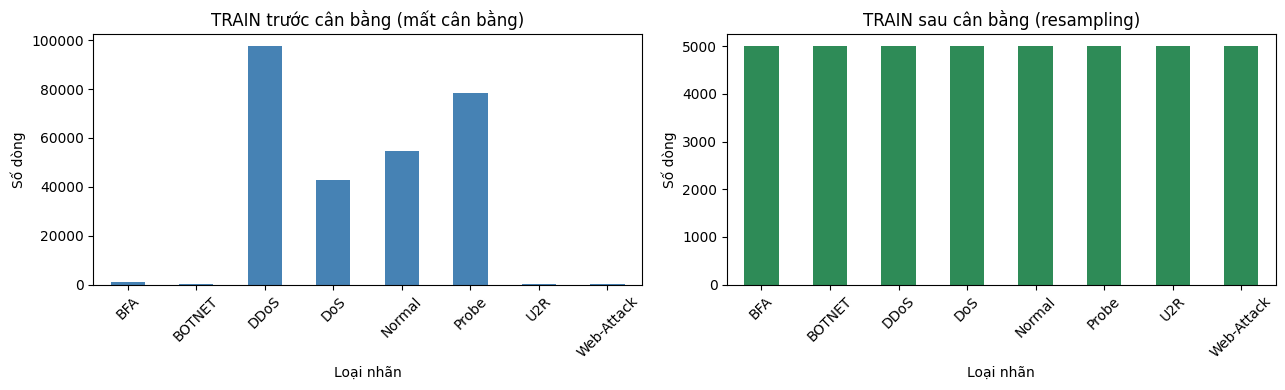

Kiểm tra train đã cân bằng: True


In [9]:
# Tạo bảng TRAIN gồm đặc trưng đã điền thiếu và nhãn gốc.
train_data = pd.DataFrame(X_train_ready, columns=used_columns)
train_data[LABEL_COL] = y_train.to_numpy()

before_counts = train_data[LABEL_COL].value_counts().sort_index()

# Resampling: giảm lớp đông / nhân bản có lặp lớp ít.
parts = []
for label in before_counts.index:
    group = train_data[train_data[LABEL_COL] == label]
    part = group.sample(
        n=SAMPLES_PER_CLASS,
        replace=(len(group) < SAMPLES_PER_CLASS),
        random_state=RANDOM_STATE
    )
    parts.append(part)

train_balanced = pd.concat(parts, ignore_index=True)
train_balanced = train_balanced.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

after_counts = train_balanced[LABEL_COL].value_counts().reindex(before_counts.index)
print("Số dòng TRAIN trước:", len(train_data), "| Sau cân bằng:", len(train_balanced))
display(pd.DataFrame({
    "Train trước": before_counts,
    "Train sau": after_counts,
    "Test (không đổi)": y_test.value_counts().reindex(before_counts.index)
}).fillna(0).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
before_counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("TRAIN trước cân bằng (mất cân bằng)")
after_counts.plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("TRAIN sau cân bằng (resampling)")
for ax in axes:
    ax.set_xlabel("Loại nhãn")
    ax.set_ylabel("Số dòng")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Dữ liệu dùng huấn luyện; X_test_ready và y_test_encoded không thay đổi.
X_train_balanced = train_balanced.drop(columns=LABEL_COL).to_numpy()
y_train_balanced = encoder.transform(train_balanced[LABEL_COL])
print("Kiểm tra train đã cân bằng:", after_counts.nunique() == 1)
assert np.isfinite(X_train_balanced).all(), "Train còn NaN/inf."


## 5. Phương pháp tiếp cận

### 5.1. Huấn luyện multiclass trước

Ba mô hình dùng **chung tập train đã cân bằng**, còn tập test là dữ liệu gốc (80/20, `stratify`). Không kết hợp thêm `class_weight="balanced"` vì bước này **đã resampling**.

**Luồng xử lý:** CSV → EDA → bỏ trùng & làm sạch `NaN/inf` → chia train/test → điền thiếu → **resampling train** → huấn luyện đa lớp → dự đoán đa lớp → quy đổi Normal/Attack → đánh giá cả hai bài toán.


In [10]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=RANDOM_STATE,
                             tree_method="hist", n_jobs=-1, eval_metric="mlogloss")
}

# Lưu dự đoán multiclass để quy đổi tiếp sang binary.
predictions = {}
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    predictions[name] = model.predict(X_test_ready)
    print("Đã huấn luyện và dự đoán:", name)


Đã huấn luyện và dự đoán: Decision Tree
Đã huấn luyện và dự đoán: Random Forest
Đã huấn luyện và dự đoán: XGBoost


## 6. Thực nghiệm và đánh giá kết quả

### 6.1. Đánh giá **multiclass** (phân loại từng loại tấn công)

- **Accuracy:** tỷ lệ dự đoán đúng toàn bộ mẫu.
- **Precision/Recall/F1 Macro:** lấy trung bình đều trên các lớp, vì vậy chú ý cả lớp ít mẫu.
- **Confusion Matrix:** thấy lớp nào dễ bị nhầm lẫn.

**Đánh giá multiclass trước**, sau đó mới đánh giá binary ở phần 6.3.

In [11]:
multi_rows = []
for name, y_pred in predictions.items():
    multi_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test_encoded, y_pred),
        "Precision Macro": precision_score(y_test_encoded, y_pred, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test_encoded, y_pred, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_test_encoded, y_pred, average="macro", zero_division=0)
    })

multi_results = pd.DataFrame(multi_rows).set_index("Mô hình")
print("BẢNG ĐÁNH GIÁ MULTICLASS")
display(multi_results.round(4))

BẢNG ĐÁNH GIÁ MULTICLASS


,Accuracy,Precision Macro,Recall Macro,F1 Macro
Mô hình,,,,
Decision Tree,0.9987,0.8634,0.9572,0.8916
Random Forest,0.9984,0.9083,0.9988,0.9423
XGBoost,0.9990,0.8801,0.9991,0.9032


### 6.2. Classification Report và Confusion Matrix — multiclass

Xem Precision/Recall/F1 **của từng nhãn** (nhất là BOTNET, U2R). Số mẫu của một lớp được thể hiện ở cột `support`.


========== Decision Tree — MULTICLASS ==========
              precision    recall  f1-score   support

         BFA       0.98      1.00      0.99       281
      BOTNET       0.94      1.00      0.97        33
        DDoS       1.00      1.00      1.00     24389
         DoS       1.00      1.00      1.00     10723
      Normal       1.00      1.00      1.00     13685
       Probe       1.00      1.00      1.00     19626
         U2R       0.18      0.67      0.29         3
  Web-Attack       0.81      1.00      0.89        38

    accuracy                           1.00     68778
   macro avg       0.86      0.96      0.89     68778
weighted avg       1.00      1.00      1.00     68778



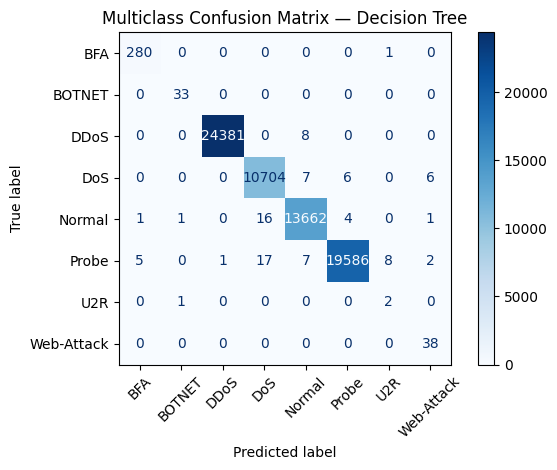


========== Random Forest — MULTICLASS ==========
              precision    recall  f1-score   support

         BFA       0.87      1.00      0.93       281
      BOTNET       1.00      1.00      1.00        33
        DDoS       1.00      1.00      1.00     24389
         DoS       1.00      1.00      1.00     10723
      Normal       1.00      1.00      1.00     13685
       Probe       1.00      1.00      1.00     19626
         U2R       0.50      1.00      0.67         3
  Web-Attack       0.90      1.00      0.95        38

    accuracy                           1.00     68778
   macro avg       0.91      1.00      0.94     68778
weighted avg       1.00      1.00      1.00     68778



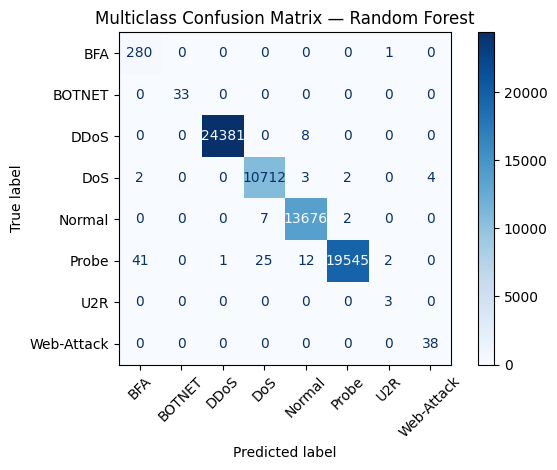


========== XGBoost — MULTICLASS ==========
              precision    recall  f1-score   support

         BFA       0.99      1.00      0.99       281
      BOTNET       0.97      1.00      0.99        33
        DDoS       1.00      1.00      1.00     24389
         DoS       1.00      1.00      1.00     10723
      Normal       1.00      1.00      1.00     13685
       Probe       1.00      1.00      1.00     19626
         U2R       0.18      1.00      0.30         3
  Web-Attack       0.90      1.00      0.95        38

    accuracy                           1.00     68778
   macro avg       0.88      1.00      0.90     68778
weighted avg       1.00      1.00      1.00     68778



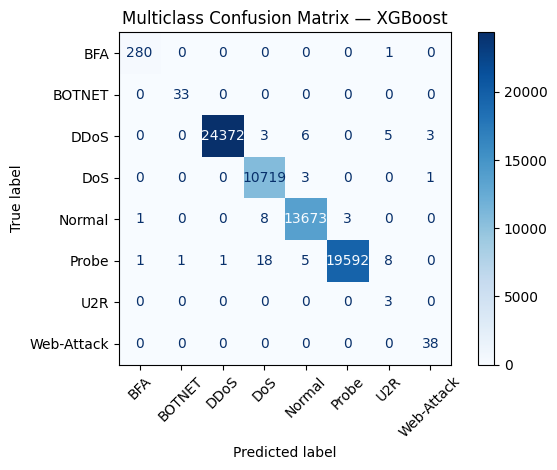

In [12]:
for name, y_pred in predictions.items():
    print("\n==========", name, "— MULTICLASS ==========")
    print(classification_report(
        y_test_encoded, y_pred,
        labels=np.arange(len(encoder.classes_)),
        target_names=encoder.classes_, zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test_encoded, y_pred,
        labels=np.arange(len(encoder.classes_)),
        display_labels=encoder.classes_,
        xticks_rotation=45, cmap="Blues", values_format="d"
    )
    plt.title("Multiclass Confusion Matrix — " + name)
    plt.tight_layout()
    plt.show()

### 6.3. Đánh giá **binary** (Normal / Attack) từ kết quả multiclass

Sau khi các mô hình đã dự đoán nhãn nhiều lớp, quy đổi như sau:

| Nhãn multiclass | Nhãn binary |
|---|---|
| `Normal` | **0 — Normal** |
| Mọi loại tấn công khác | **1 — Attack** |

**Quan trọng:** Không huấn luyện mô hình binary mới. `y_test_binary` và `binary_predictions` đều được suy ra từ **cùng dòng test** và **các dự đoán multiclass đã có**.

Trong Precision, Recall và F1 nhị phân, lớp dương (positive) là **Attack = 1**.

In [13]:
# Nhãn thật binary của cùng tập test.
y_test_binary = (y_test.to_numpy() != "Normal").astype(int)

# Đổi từ mã số đa lớp -> tên nhãn -> 0 (Normal) / 1 (Attack).
binary_predictions = {}
binary_rows = []

for name, y_pred in predictions.items():
    predicted_labels = encoder.inverse_transform(y_pred)
    y_pred_binary = (predicted_labels != "Normal").astype(int)
    binary_predictions[name] = y_pred_binary

    binary_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test_binary, y_pred_binary),
        "Precision (Attack)": precision_score(y_test_binary, y_pred_binary, zero_division=0),
        "Recall (Attack)": recall_score(y_test_binary, y_pred_binary, zero_division=0),
        "F1 (Attack)": f1_score(y_test_binary, y_pred_binary, zero_division=0)
    })

binary_results = pd.DataFrame(binary_rows).set_index("Mô hình")
print("BẢNG ĐÁNH GIÁ BINARY — suy ra từ multiclass")
display(binary_results.round(4))

BẢNG ĐÁNH GIÁ BINARY — suy ra từ multiclass


,Accuracy,Precision (Attack),Recall (Attack),F1 (Attack)
Mô hình,,,,
Decision Tree,0.9993,0.9996,0.9996,0.9996
Random Forest,0.9995,0.9998,0.9996,0.9997
XGBoost,0.9996,0.9998,0.9997,0.9998


### 6.4. Classification Report và Confusion Matrix — binary

Ma trận nhầm lẫn 2×2 cho thấy số lượng `Normal` bị báo động nhầm và số `Attack` bị bỏ sót.


========== Decision Tree — BINARY ==========
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     13685
      Attack       1.00      1.00      1.00     55093

    accuracy                           1.00     68778
   macro avg       1.00      1.00      1.00     68778
weighted avg       1.00      1.00      1.00     68778



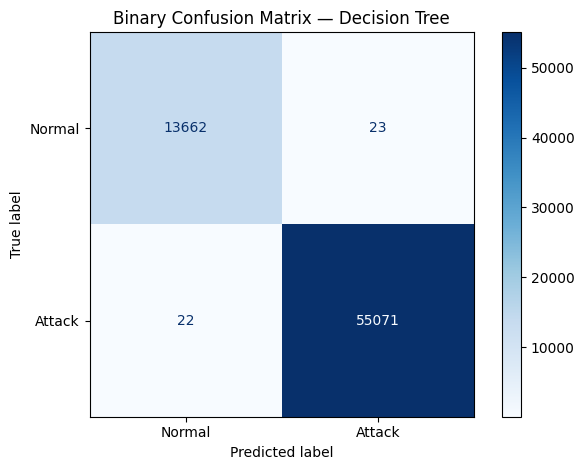


========== Random Forest — BINARY ==========
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     13685
      Attack       1.00      1.00      1.00     55093

    accuracy                           1.00     68778
   macro avg       1.00      1.00      1.00     68778
weighted avg       1.00      1.00      1.00     68778



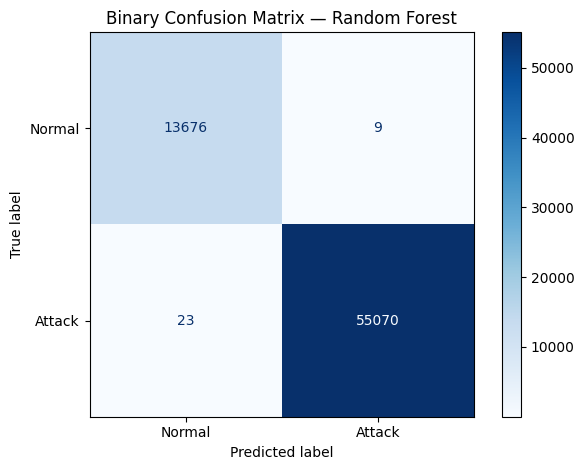


========== XGBoost — BINARY ==========
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     13685
      Attack       1.00      1.00      1.00     55093

    accuracy                           1.00     68778
   macro avg       1.00      1.00      1.00     68778
weighted avg       1.00      1.00      1.00     68778



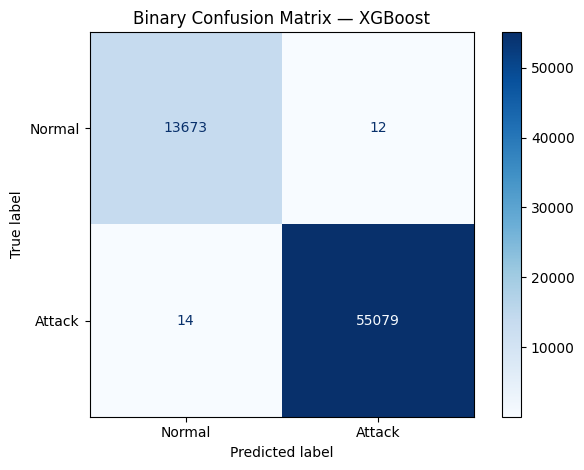

In [14]:
for name, y_pred_binary in binary_predictions.items():
    print("\n==========", name, "— BINARY ==========")
    print(classification_report(
        y_test_binary, y_pred_binary,
        labels=[0, 1], target_names=["Normal", "Attack"], zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test_binary, y_pred_binary, labels=[0, 1],
        display_labels=["Normal", "Attack"], cmap="Blues", values_format="d"
    )
    plt.title("Binary Confusion Matrix — " + name)
    plt.tight_layout()
    plt.show()

### 6.5. So sánh nhanh ba mô hình

Đọc **F1 Macro multiclass** để đánh giá độ cân bằng giữa các loại tấn công; đọc **F1 (Attack) binary** để đánh giá khả năng nhận biết có tấn công hay không. Hai điểm này đo các mục tiêu khác nhau nên không so sánh trực tiếp với nhau như cùng một thước đo.

,F1 Macro (Multiclass),F1 Attack (Binary)
Mô hình,,
Decision Tree,0.8916,0.9996
Random Forest,0.9423,0.9997
XGBoost,0.9032,0.9998


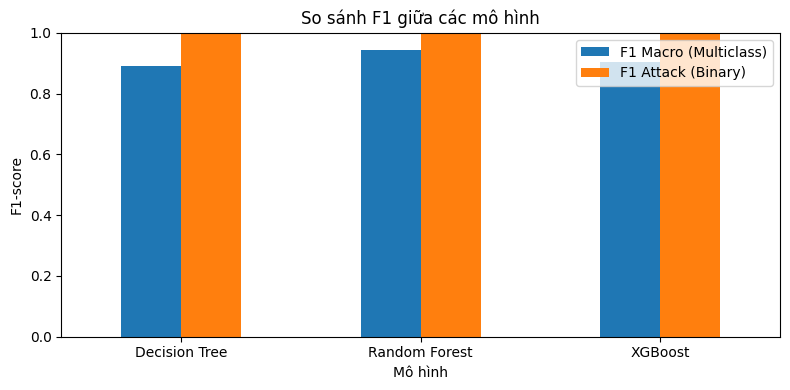

In [15]:
compare = pd.DataFrame({
    "F1 Macro (Multiclass)": multi_results["F1 Macro"],
    "F1 Attack (Binary)": binary_results["F1 (Attack)"]
})
display(compare.round(4))
compare.plot(kind="bar", figsize=(8, 4), ylim=(0, 1))
plt.title("So sánh F1 giữa các mô hình")
plt.ylabel("F1-score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Phân tích và thảo luận (điền sau khi chạy)

### 7.1. EDA, làm sạch và cân bằng

- Số giá trị NaN ban đầu: **[...]**, số giá trị vô hạn: **[...]**.
- Sau khi thay inf và điền median, số NaN/inf còn lại trong train/test: **[...]**.
- Trước resampling, lớp **[...]** có nhiều nhất, **[...]** ít nhất.
- Sau resampling, mỗi lớp có **[...]** dòng train; **test vẫn giữ phân bố gốc**.

### 7.2. Kết quả multiclass

- Mô hình có **Macro F1** cao nhất: **[...]**, đạt **[...]**.
- Những lớp có Recall thấp: **[...]**. Kiểm tra Confusion Matrix để xem chúng nhầm với lớp nào.

### 7.3. Kết quả binary

- Mô hình có **F1 (Attack)** cao nhất: **[...]**, đạt **[...]**.
- Số Attack bị dự đoán thành Normal (bỏ sót) là **[...]**; số Normal bị nhận nhầm Attack là **[...]**.

### 7.4. Hạn chế

- Việc các cột trên biểu đồ sau resampling cao bằng nhau **chỉ chứng minh cân bằng số lượng mẫu train**, không đảm bảo mô hình dự đoán lớp hiếm tốt.
- Lớp hiếm như U2R có rất ít mẫu thật; oversampling chỉ lặp mẫu, dễ dẫn đến overfitting.
- Giảm số dòng của lớp lớn cũng có thể làm mất thông tin. Có thể thử mức `SAMPLES_PER_CLASS` khác để xem ảnh hưởng.
- Binary **suy ra từ multiclass**, chưa phải mô hình binary train riêng.


## 8. Kết luận và hướng phát triển

**Kết luận (điền sau khi chạy):** Nhóm đã thực hiện EDA, làm sạch `NaN/null/inf`, chia train/test, điền giá trị thiếu, cân bằng tập train bằng undersampling và oversampling, rồi huấn luyện ba mô hình multiclass. Trên cùng tập test, nhóm đánh giá thêm binary theo cách gộp nhãn `Normal/Attack`. Kết quả cho thấy **[...]**.

**Hướng phát triển:** So sánh thử với cách dùng `class_weight` không resampling; thu thập thêm mẫu thực cho U2R/BOTNET; thử chọn mức resampling khác; xây dựng giao diện demo nhập network flow.


## 9. Đóng góp của các thành viên

*Nhóm tự điền theo công việc thực tế.*

| Thành viên | Công việc | Tỷ lệ đóng góp |
|---|---|---|
| [...] | Khảo sát dữ liệu, EDA | [...] |
| [...] | Tiền xử lý và xử lý mất cân bằng | [...] |
| [...] | Huấn luyện, đánh giá và báo cáo | [...] |

## 10. Tài liệu tham khảo

1. Elsayed, M. S., Le-Khac, N.-A., & Jurcut, A. D. (2020). *InSDN: A Novel SDN Intrusion Dataset*. IEEE Access, 8, 165263–165284. https://doi.org/10.1109/ACCESS.2020.3022633
2. Scikit-learn — `train_test_split`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
3. Scikit-learn — `class_weight` và `compute_sample_weight`: https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html
4. Scikit-learn — Classification metrics: https://scikit-learn.org/stable/modules/model_evaluation.html
5. XGBoost — Python API (`XGBClassifier` và `sample_weight`): https://xgboost.readthedocs.io/en/stable/python/python_api.html